In [1]:

import yfinance as yf
import pandas as pd
from pathlib import Path

# Download the historical data again
ticker = "CSV"

df = yf.download(
    ticker,
    start="2016-10-28",
    end="2026-10-29",
    interval="1d",
    auto_adjust=False,
    progress=False
)

# Check whether the download returned data
if df.empty:
    print("No data was returned. We need to check the ticker.")
else:
    # Flatten multi-level column headings if necessary
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # Convert the date index into a column
    df = df.reset_index()

    # Display the results
    print("Dataset shape:", df.shape)
    print("Column names:", df.columns.tolist())
    display(df.head())


Dataset shape: (2513, 7)
Column names: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-28,20.742783,23.570000,24.250000,23.430000,23.870001,131400
1,2016-10-31,20.804382,23.639999,23.770000,23.440001,23.600000,118700
2,2016-11-01,20.628382,23.440001,23.840000,23.360001,23.670000,144900
3,2016-11-02,20.672377,23.490000,23.860001,23.420000,23.440001,123700
4,2016-11-03,20.601974,23.410000,23.860001,23.379999,23.480000,82600


In [2]:

from pathlib import Path

Path("data").mkdir(exist_ok=True)

df.to_csv("data/CSV_stock_data_formatted.csv", index=False)

print("Dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Column names:", df.columns.tolist())


Dataset saved successfully!
Rows: 2513
Columns: 7
Column names: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


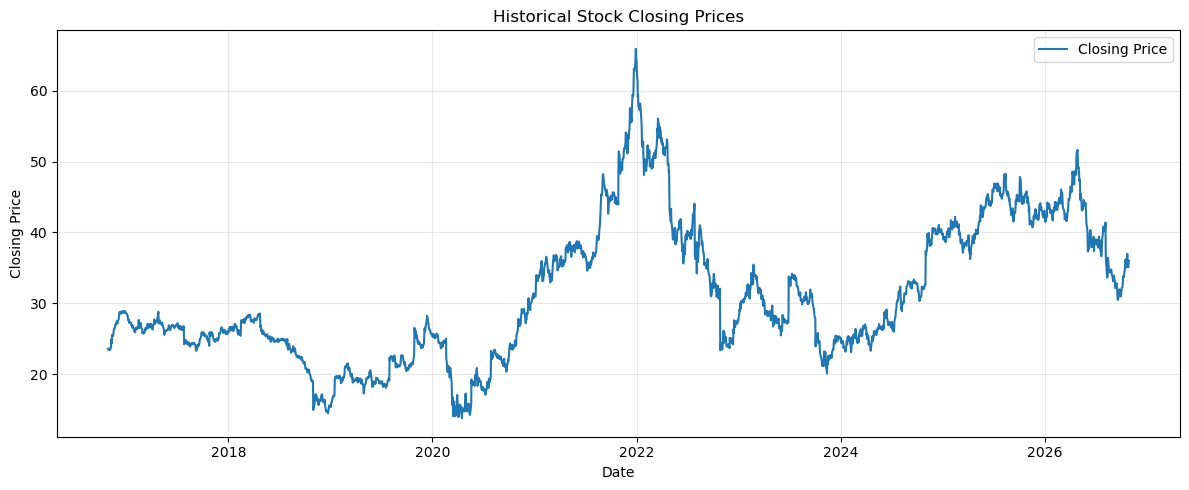

In [3]:

import matplotlib.pyplot as plt
import pandas as pd

# Convert Date into a datetime variable
df["Date"] = pd.to_datetime(df["Date"])

# Sort observations chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Plot historical closing prices
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"], label="Closing Price")

plt.title("Historical Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Daily return summary:


count    2512.000000
mean        0.044799
std         2.356484
min       -27.034612
25%        -1.069559
50%         0.000000
75%         1.054411
max        22.039269
Name: Daily_Return, dtype: float64

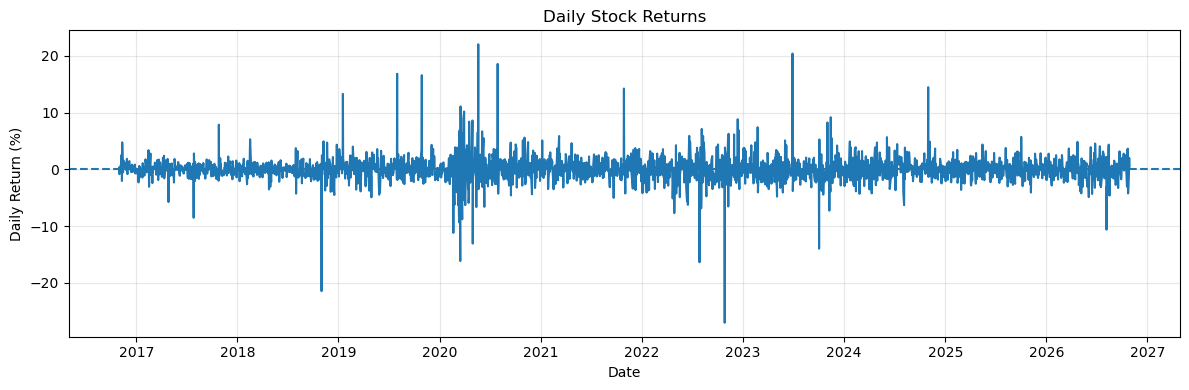

In [4]:

# Calculate daily percentage returns
df["Daily_Return"] = df["Close"].pct_change() * 100

# Summary statistics
print("Daily return summary:")
display(df["Daily_Return"].describe())

# Plot daily returns
plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Daily_Return"])
plt.axhline(0, linestyle="--")
plt.title("Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:

print("Dataset dimensions:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nDuplicate dates:", df["Date"].duplicated().sum())


Dataset dimensions: (2513, 8)

Missing values:
Price
Date            0
Adj Close       0
Close           0
High            0
Low             0
Open            0
Volume          0
Daily_Return    1
dtype: int64

Date range:
2016-10-28 00:00:00 to 2026-10-28 00:00:00

Duplicate dates: 0


#### Exploratory Data Analysis: Daily Returns

The dataset contains 2,513 daily price observations and 2,512 calculated daily returns.
The mean daily return is approximately 0.0447%, while the standard deviation is 2.3565%, indicating variability in daily price movements.
The observed minimum and maximum daily returns are −27.03% and +22.04%, respectively.
These extreme values require further investigation to determine whether they reflect genuine market movements or data-related effects.

These descriptive statistics provide an initial understanding of return behaviour and help inform subsequent data preparation and clustering.
They do not, by themselves, establish a trend, seasonality or forecasting accuracy.

In [6]:

# Find the five largest positive daily returns
print("Largest positive returns:")
display(
    df.nlargest(5, "Daily_Return")[
        ["Date", "Close", "Adj Close", "Daily_Return"]
    ]
)

# Find the five largest negative daily returns
print("Largest negative returns:")
display(
    df.nsmallest(5, "Daily_Return")[
        ["Date", "Close", "Adj Close", "Daily_Return"]
    ]
)


Largest positive returns:


Price,Date,Close,Adj Close,Daily_Return
894,2020-05-20,19.270000,17.764027,22.039269
1676,2023-06-29,33.759998,32.355118,20.399419
942,2020-07-29,23.299999,21.479080,18.575062
692,2019-08-01,22.340000,20.301559,16.841000
754,2019-10-29,26.559999,24.216866,16.593497


Largest negative returns:


Price,Date,Close,Adj Close,Daily_Return
1509,2022-10-27,23.400000,22.147202,-27.034612
506,2018-11-01,14.970000,13.438755,-21.458548
1445,2022-07-28,36.840000,34.752567,-16.367762
848,2020-03-16,14.070000,12.906709,-16.150184
1742,2023-10-03,23.940001,23.026743,-13.977720


#### Analysis of the Largest Daily Returns

The results show that the largest daily gain was approximately 22.04% on 20 May 2020,
while the largest daily loss was approximately -27.03% on 27 October 2022.
Other large movements occurred on different dates throughout the dataset.
    
These results show that daily returns can vary considerably. 
The extreme values should be checked before deciding whether they represent genuine market movements
or possible data issues.

In [7]:

# Select the columns for clustering

cluster_data = df[["Daily_Return", "Volume", "Close"]].dropna()

print("Rows available for clustering:", len(cluster_data))

display(cluster_data.head())


Rows available for clustering: 2512


Price,Daily_Return,Volume,Close
1,0.296986,118700,23.639999
2,-0.846019,144900,23.440001
3,0.213307,123700,23.490000
4,-0.340570,82600,23.410000
5,0.299016,98500,23.480000


In [8]:

from sklearn.preprocessing import StandardScaler

# Scale the selected features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

print("Original data shape:", cluster_data.shape)
print("Scaled data shape:", scaled_data.shape)

# Show the first five scaled rows
print(scaled_data[:5])


Original data shape: (2512, 3)
Scaled data shape: (2512, 3)
[[ 0.10703997  0.05560761 -0.78059285]
 [-0.37810348  0.39109892 -0.80117903]
 [ 0.07152276  0.11963267 -0.79603254]
 [-0.16356804 -0.40665332 -0.80426705]
 [ 0.10790151 -0.20305363 -0.79706187]]


In [9]:

from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assign each row to a cluster
cluster_labels = kmeans.fit_predict(scaled_data)

# Add the cluster labels to our clustering table
cluster_data = cluster_data.copy()
cluster_data["Cluster"] = cluster_labels

print("Number of observations in each cluster:")
print(cluster_data["Cluster"].value_counts().sort_index())

display(cluster_data.head())


Number of observations in each cluster:
Cluster
0     169
1     839
2    1504
Name: count, dtype: int64


C:\Users\nomin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\nomin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\nomin\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\nomin\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\nomin\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Price,Daily_Return,Volume,Close,Cluster
1,0.296986,118700,23.639999,2
2,-0.846019,144900,23.440001,2
3,0.213307,123700,23.490000,2
4,-0.340570,82600,23.410000,2
5,0.299016,98500,23.480000,2



# Calculate the average values in each cluster
cluster_summary = cluster_data.groupby("Cluster")[
    ["Daily_Return", "Volume", "Close"]
].mean()

display(cluster_summary)


In [10]:
from threadpoolctl import threadpool_limits

with threadpool_limits(limits=2):
    cluster_labels = kmeans.fit_predict(scaled_data)

### K-Means Cluster Analysis

K-Means divided the observations into three clusters using daily returns, trading volume and closing price. Cluster 0 had the highest average daily return (approximately 1.40%) and the highest average trading volume. Cluster 1 had an average daily return close to zero and the highest average closing price. Cluster 2 had a slightly negative average daily return and the lowest average closing price.

The results suggest that the groups have different characteristics. However, these averages alone do not explain why the market behaved differently on those days.

In [11]:

from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(scaled_data, cluster_labels)
db_index = davies_bouldin_score(scaled_data, cluster_labels)

print("K-Means Silhouette Score:", round(silhouette, 3))
print("K-Means Davies-Bouldin Index:", round(db_index, 3))


K-Means Silhouette Score: 0.362
K-Means Davies-Bouldin Index: 1.084


### K-Means Evaluation

The K-Means model achieved a Silhouette Score of 0.362 and a Davies–Bouldin Index of 1.084. The Silhouette Score suggests that some separation exists between the clusters, although the groups are not completely distinct. The Davies–Bouldin Index will be compared with the result from a second clustering algorithm to help decide which method performs better on this dataset.


In [12]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Create three clusters using Agglomerative Clustering
agg_model = AgglomerativeClustering(n_clusters=3)

agg_labels = agg_model.fit_predict(scaled_data)

# Evaluate the clustering
agg_silhouette = silhouette_score(scaled_data, agg_labels)
agg_db_index = davies_bouldin_score(scaled_data, agg_labels)

print("Agglomerative Silhouette Score:", round(agg_silhouette, 3))
print("Agglomerative Davies-Bouldin Index:", round(agg_db_index, 3))


Agglomerative Silhouette Score: 0.306
Agglomerative Davies-Bouldin Index: 1.213


### Comparison of Clustering Algorithms

K-Means achieved a Silhouette Score of 0.362 and a Davies–Bouldin Index of 1.084. Agglomerative Clustering achieved a Silhouette Score of 0.306 and a Davies–Bouldin Index of 1.213.

Based on these results, K-Means performed better than Agglomerative Clustering on both evaluation measures. Its higher Silhouette Score suggests better separation between clusters, while its lower Davies–Bouldin Index suggests better-defined groups. However, the scores do not indicate perfect separation, so the results should be interpreted with care.

       Algorithm  Silhouette Score  Davies-Bouldin Index
0        K-Means          0.362365              1.083828
1  Agglomerative          0.305642              1.212901


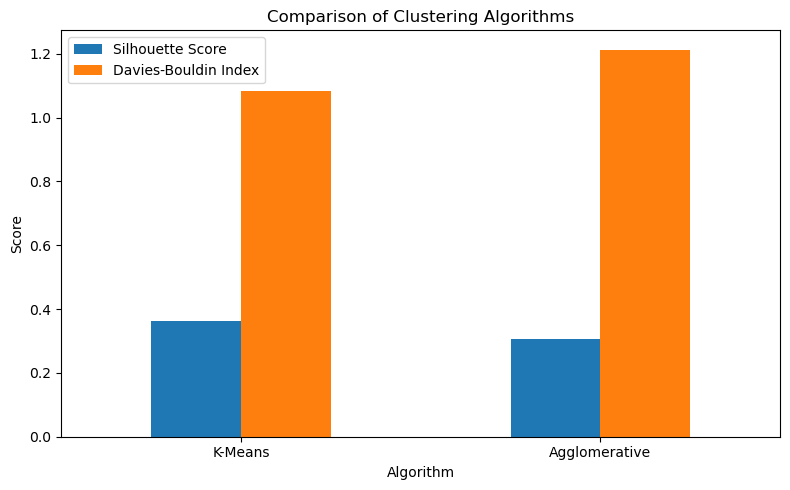

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

scores = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative"],
    "Silhouette Score": [silhouette, agg_silhouette],
    "Davies-Bouldin Index": [db_index, agg_db_index]
})

print(scores)

scores.plot(
    x="Algorithm",
    y=["Silhouette Score", "Davies-Bouldin Index"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparison of Clustering Algorithms")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


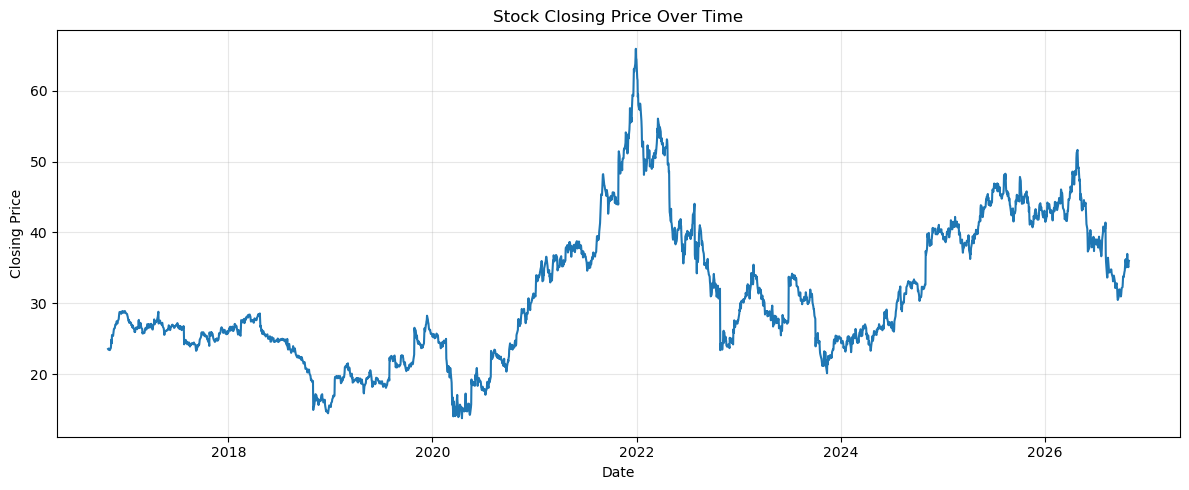

Start date: 2016-10-28 00:00:00
End date: 2026-10-28 00:00:00
Number of observations: 2513


In [14]:

# Set the date as the index for time-series analysis
ts_data = df[["Date", "Close"]].copy()

ts_data["Date"] = pd.to_datetime(ts_data["Date"])
ts_data = ts_data.set_index("Date").sort_index()

# Plot the closing price over time
plt.figure(figsize=(12, 5))
plt.plot(ts_data.index, ts_data["Close"])
plt.title("Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Start date:", ts_data.index.min())
print("End date:", ts_data.index.max())
print("Number of observations:", len(ts_data))


Average closing price by year:


Date
2016-12-31    26.854546
2017-12-31    26.038765
2018-12-31    23.508486
2019-12-31    20.863333
2020-12-31    21.704308
2021-12-31    41.159921
2022-12-31    40.043068
2023-12-31    28.685720
2024-12-31    29.837817
2025-12-31    42.565840
2026-12-31    40.267874
Freq: YE-DEC, Name: Close, dtype: float64

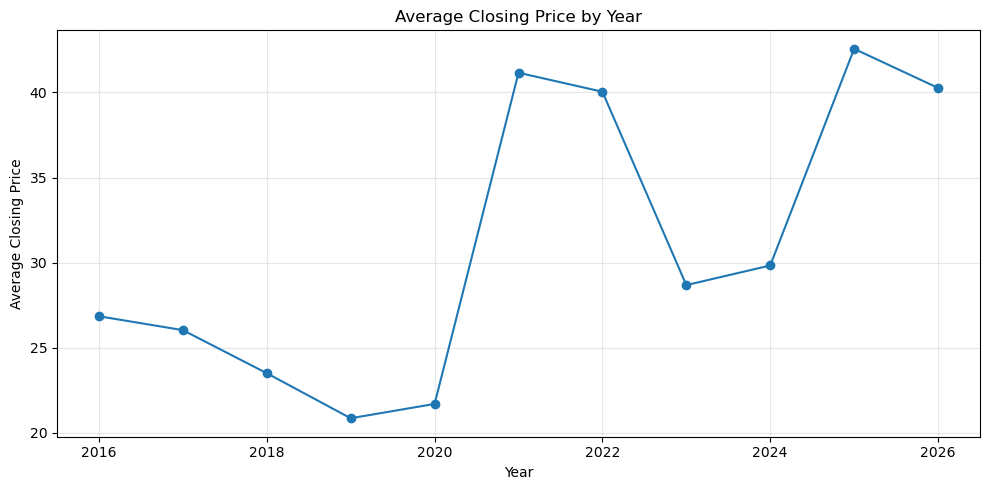

In [15]:

# Calculate the average closing price for each year
yearly_average = ts_data["Close"].resample("YE").mean()

print("Average closing price by year:")
display(yearly_average)

# Plot the yearly averages
plt.figure(figsize=(10, 5))
plt.plot(yearly_average.index.year, yearly_average.values, marker="o")
plt.title("Average Closing Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Yearly Trend Analysis

The yearly average closing prices show changes over the period studied. The average generally decreased between 2016 and 2019 before increasing in 2020 and 2021. It then decreased in 2022 and 2023, followed by increases in 2024 and 2025. The available 2026 average remains relatively high, although the year is incomplete.

Overall, the data shows that the closing price did not follow a consistent upward or downward trend. This yearly analysis helps identify longer-term changes, but further analysis is needed to investigate seasonality.

Average closing price by month:


Jan    32.142857
Feb    32.358743
Mar    32.127900
Apr    31.615777
May    30.447123
Jun    30.498373
Jul    31.145377
Aug    31.332986
Sep    30.953039
Oct    30.177432
Nov    29.675658
Dec    32.292967
Name: Close, dtype: float64

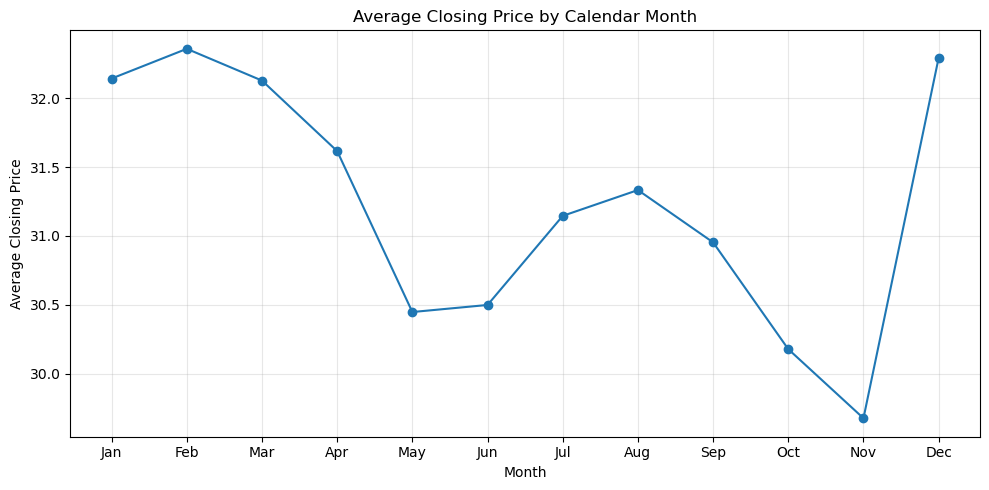

In [16]:

# Calculate the average closing price for each calendar month
monthly_average = ts_data.groupby(
    ts_data.index.month
)["Close"].mean()

# Use month names on the chart
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_average.index = month_names

print("Average closing price by month:")
display(monthly_average)

plt.figure(figsize=(10, 5))
plt.plot(monthly_average.index, monthly_average.values, marker="o")
plt.title("Average Closing Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Monthly Pattern Analysis

The monthly averages show some differences in closing prices across the calendar year. February had the highest average closing price at approximately 32.36, while November had the lowest at approximately 29.68. December also had a relatively high average of approximately 32.29.

However, these differences do not prove that the stock has a seasonal pattern. The monthly averages combine observations from different years, so further time-series analysis is needed to investigate seasonality.

In [17]:

# Use the closing price for forecasting
price_series = ts_data["Close"].dropna()

# Use the first 80% for training and the last 20% for testing
split_point = int(len(price_series) * 0.8)

train = price_series.iloc[:split_point]
test = price_series.iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())


Training observations: 2010
Testing observations: 503
Training ends: 2024-10-24 00:00:00
Testing starts: 2024-10-25 00:00:00


In [18]:
# Use a regular business-day frequency for the time series
price_series = ts_data["Close"].asfreq("B").ffill()

# Split the data again in date order
split_point = int(len(price_series) * 0.8)

train = price_series.iloc[:split_point]
test = price_series.iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 2087
Testing observations: 522


Mean Absolute Error (MAE): 8.771
Root Mean Squared Error (RMSE): 9.584


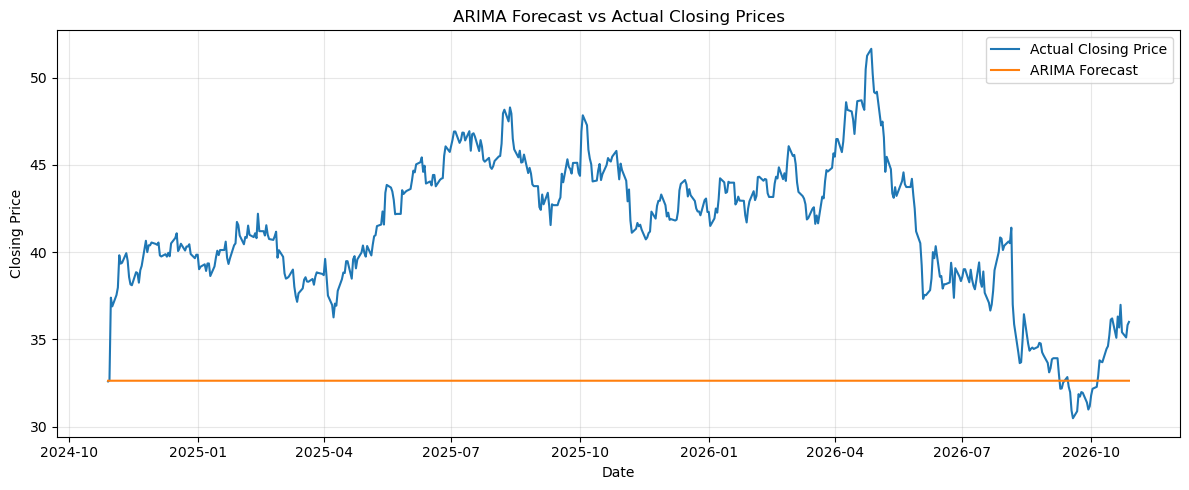

In [19]:

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Fit the ARIMA model
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

# Forecast the testing period
forecast = model_fit.forecast(steps=len(test))

# Evaluate the forecast
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))

# Plot actual and forecast prices
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual Closing Price")
plt.plot(test.index, forecast.values, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### ARIMA Forecast Evaluation

An ARIMA(1,1,1) model was used to forecast the closing price. The model achieved a Mean Absolute Error (MAE) of 8.771 and a Root Mean Squared Error (RMSE) of 9.584 on the testing data. These results indicate that the forecasts differed from the actual closing prices by a noticeable amount.

The RMSE is higher than the MAE, which suggests that some larger errors affected the evaluation. Overall, the model provides a starting point for forecasting, but its accuracy could be improved by testing other ARIMA parameters. The results should also be interpreted with care because missing weekdays were filled using the previous closing price.

In [20]:

# Try a second ARIMA model
model_2 = ARIMA(train, order=(2, 1, 1))
model_fit_2 = model_2.fit()

forecast_2 = model_fit_2.forecast(steps=len(test))

mae_2 = mean_absolute_error(test, forecast_2)
rmse_2 = np.sqrt(mean_squared_error(test, forecast_2))

print("ARIMA(2,1,1) MAE:", round(mae_2, 3))
print("ARIMA(2,1,1) RMSE:", round(rmse_2, 3))


ARIMA(2,1,1) MAE: 8.756
ARIMA(2,1,1) RMSE: 9.568


### Comparison of ARIMA Models

Two ARIMA models were tested using the same training and testing data. ARIMA(1,1,1) achieved an MAE of 8.771 and an RMSE of 9.584. ARIMA(2,1,1) achieved an MAE of 8.756 and an RMSE of 9.568.

ARIMA(2,1,1) performed slightly better because both error measures were lower. However, the difference was small. Based on these two tests, ARIMA(2,1,1) is the better option, although additional testing would be needed to determine whether it provides a reliable improvement.

,Model,MAE,RMSE
0,"ARIMA(1,1,1)",8.771480,9.583761
1,"ARIMA(2,1,1)",8.755795,9.568312


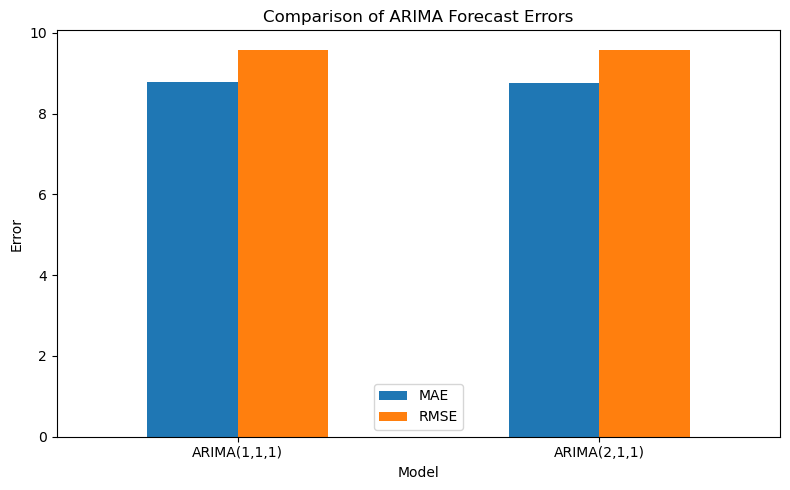

In [21]:

arima_results = pd.DataFrame({
    "Model": ["ARIMA(1,1,1)", "ARIMA(2,1,1)"],
    "MAE": [mae, mae_2],
    "RMSE": [rmse, rmse_2]
})

display(arima_results)

arima_results.plot(
    x="Model",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparison of ARIMA Forecast Errors")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [25]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Build a simple seasonal forecasting model
seasonal_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 5),
    enforce_stationarity=False,
    enforce_invertibility=False
)

seasonal_fit = seasonal_model.fit(disp=False)

# Make predictions for the test period
seasonal_forecast = seasonal_fit.forecast(steps=len(test))

# Evaluate the forecast
seasonal_mae = mean_absolute_error(test, seasonal_forecast)
seasonal_rmse = np.sqrt(mean_squared_error(test, seasonal_forecast))

print("SARIMA model results")
print("MAE:", round(seasonal_mae, 3))
print("RMSE:", round(seasonal_rmse, 3))


SARIMA model results
MAE: 7.819
RMSE: 8.601


,Model,MAE,RMSE
0,"ARIMA(1,1,1)",8.771480,9.583761
1,"ARIMA(2,1,1)",8.755795,9.568312
2,SARIMA,7.818823,8.600999


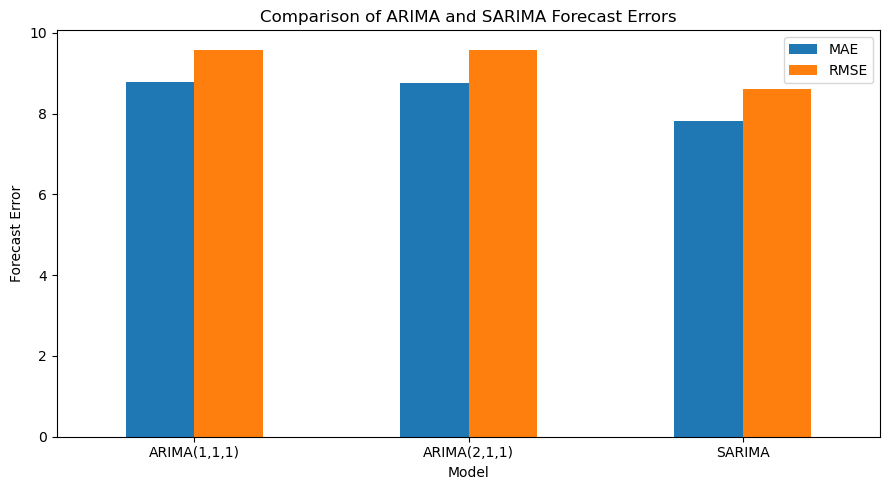

In [26]:

# Compare the three forecasting models
forecast_results = pd.DataFrame({
    "Model": ["ARIMA(1,1,1)", "ARIMA(2,1,1)", "SARIMA"],
    "MAE": [mae, mae_2, seasonal_mae],
    "RMSE": [rmse, rmse_2, seasonal_rmse]
})

display(forecast_results)

# Create a comparison chart
forecast_results.plot(
    x="Model",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparison of ARIMA and SARIMA Forecast Errors")
plt.ylabel("Forecast Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Forecasting Model Comparison

Three forecasting models were tested: ARIMA(1,1,1), ARIMA(2,1,1) and SARIMA. Their performance was compared using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Lower values indicate smaller forecast errors.

The SARIMA model achieved the lowest MAE of 7.819 and RMSE of 8.601. Therefore, it performed best among the three models tested on the selected test period. However, its performance may differ when forecasting future stock prices.

In [22]:

# Find unusually large daily price movements
upper_limit = df["Daily_Return"].mean() + 3 * df["Daily_Return"].std()
lower_limit = df["Daily_Return"].mean() - 3 * df["Daily_Return"].std()

anomalies = df[
    (df["Daily_Return"] > upper_limit) |
    (df["Daily_Return"] < lower_limit)
]

print("Upper limit:", round(upper_limit, 2), "%")
print("Lower limit:", round(lower_limit, 2), "%")
print("Number of unusual daily returns:", len(anomalies))

display(anomalies[["Date", "Close", "Daily_Return"]].head(10))


Upper limit: 7.11 %
Lower limit: -7.02 %
Number of unusual daily returns: 33


Price,Date,Close,Daily_Return
186,2017-07-27,24.230000,-8.531522
250,2017-10-26,25.900000,7.871717
506,2018-11-01,14.970000,-21.458548
557,2019-01-17,19.260000,13.294119
692,2019-08-01,22.340000,16.841000
754,2019-10-29,26.559999,16.593497
831,2020-02-20,22.200001,-11.199997
845,2020-03-11,17.330000,-7.966012
846,2020-03-12,15.710000,-9.347951
848,2020-03-16,14.070000,-16.150184


### Anomaly Detection

A simple three-standard-deviation rule was used to identify unusually large daily returns. Returns above 7.11% or below -7.02% were flagged as potential anomalies. In total, 33 observations were identified.

Some of the flagged returns were large increases, while others were large decreases. These observations may represent unusual market movements, but they could also be affected by company announcements or data-related issues. Therefore, they should be investigated rather than automatically removed from the dataset.

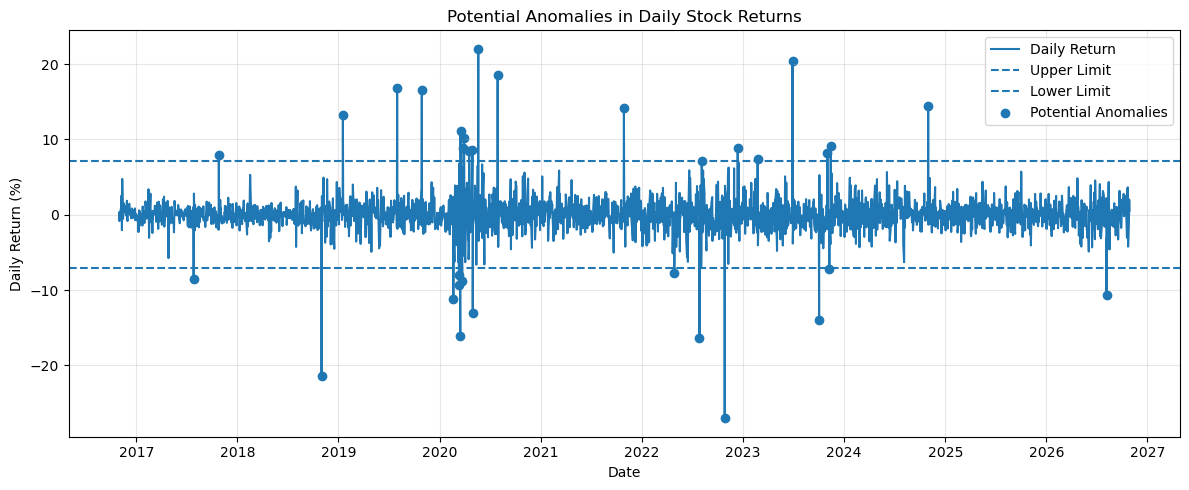

In [23]:

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Daily_Return"], label="Daily Return")
plt.axhline(upper_limit, linestyle="--", label="Upper Limit")
plt.axhline(lower_limit, linestyle="--", label="Lower Limit")

plt.scatter(
    anomalies["Date"],
    anomalies["Daily_Return"],
    label="Potential Anomalies"
)

plt.title("Potential Anomalies in Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Monthly Daily Return Analysis

The monthly average daily returns varied across the calendar year. December had the highest average daily return at approximately 0.272%, followed by July at 0.145%. September had the lowest average at approximately -0.150%, followed by April at -0.161%.

These differences suggest that average returns were not identical across months. However, this analysis alone does not confirm a repeating seasonal pattern. Further testing would be needed before concluding that the stock has reliable seasonality.

In [24]:

from pathlib import Path

# Create a folder to store the dataset
Path("data").mkdir(exist_ok=True)

# Save the dataset as a CSV file
df.to_csv("data/CSV_stock_data_formatted.csv", index=False)

print("Dataset saved successfully!")
print("File contains", len(df), "rows and", len(df.columns), "columns.")


Dataset saved successfully!
File contains 2513 rows and 8 columns.
